# HW3 Part I — Neurons by Hand
所有數值四捨五入到小數 4 位;中間量以完整精度計算、顯示時才進位。
此 notebook 不需要 GPU,也不需要任何額外檔案。

In [1]:
import numpy as np, random
import matplotlib.pyplot as plt
random.seed(0); np.random.seed(0)
r4 = lambda a: np.round(a, 4)
sigmoid = lambda z: 1 / (1 + np.exp(-z))

## (a) Architecture:網路圖與參數量

W1 = 100 x 3073 = 307,300
W2 = 10 x 101 = 1,010
Total = 308,310  (biases: 110)


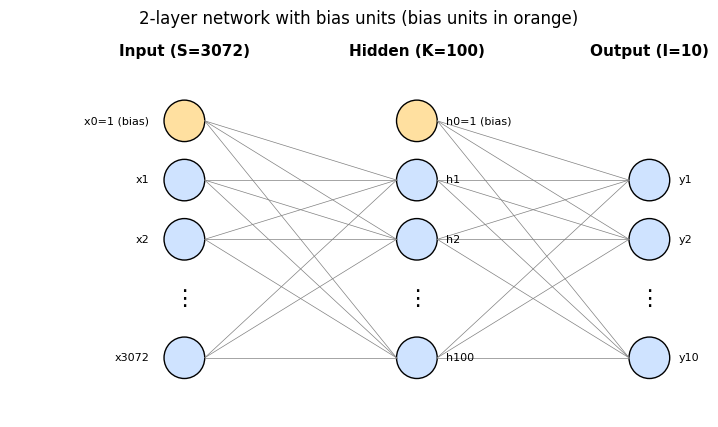

In [2]:
S, K, I = 3072, 100, 10
n1 = K * (S + 1)      # W1: K x (S+1), bias in column 0
n2 = I * (K + 1)      # W2: I x (K+1)
print(f'W1 = {K} x {S+1} = {n1:,}')
print(f'W2 = {I} x {K+1} = {n2:,}')
print(f'Total = {n1+n2:,}  (biases: {K+I})')

# schematic with bias units (only a few nodes drawn per layer)
fig, ax = plt.subplots(figsize=(9, 5)); ax.axis('off')
layers = [('Input (S=3072)',  ['x0=1 (bias)', 'x1', 'x2', '...', 'x3072']),
          ('Hidden (K=100)',  ['h0=1 (bias)', 'h1', 'h2', '...', 'h100']),
          ('Output (I=10)',   ['', 'y1', 'y2', '...', 'y10'])]
pos = {}
for li, (name, nodes) in enumerate(layers):
    ax.text(li * 4, 5.6, name, ha='center', fontsize=11, weight='bold')
    for ni, lab in enumerate(nodes):
        if lab == '': continue
        y = 4.5 - ni
        pos[(li, ni)] = (li * 4, y)
        if lab == '...':
            ax.text(li * 4, y, '⋮', ha='center', va='center', fontsize=16); continue
        isb = 'bias' in lab
        ax.add_patch(plt.Circle((li * 4, y), 0.35, fc='#ffe0a0' if isb else '#cfe3ff', ec='k'))
        ax.text(li * 4 - 0.6, y, lab, ha='right', va='center', fontsize=8) if li == 0 else ax.text(li * 4 + 0.5, y, lab, ha='left', va='center', fontsize=8)
for li in range(2):
    for a in range(5):
        for b in range(1, 5):
            if (li, a) in pos and (li + 1, b) in pos and layers[li][1][a] != '...' and layers[li+1][1][b] != '...':
                (x0, y0), (x1, y1) = pos[(li, a)], pos[(li + 1, b)]
                ax.plot([x0 + .35, x1 - .35], [y0, y1], color='gray', lw=.5)
ax.set_xlim(-3, 9); ax.set_ylim(-0.5, 6)
ax.set_title('2-layer network with bias units (bias units in orange)'); plt.show()

## (b) Backpropagation(玩具網路 2-2-1)

In [3]:
x  = np.array([1.0, 0.5]); y = 1.0
W1 = np.array([[0.1, 0.3], [0.2, 0.4]]); b1 = np.zeros(2)
W2 = np.array([[0.5, -0.3]]);            b2 = np.zeros(1)
lr = 0.5

def forward(W1, b1, W2, b2):
    z1 = W1 @ x + b1; h = sigmoid(z1); yhat = (W2 @ h + b2)[0]
    return z1, h, yhat, 0.5 * (y - yhat) ** 2

z1, h, yhat, J = forward(W1, b1, W2, b2)
print('z1 =', r4(z1)); print('h  =', r4(h)); print('y_hat =', r4(yhat)); print('J =', r4(J))

d2 = yhat - y
sp = h * (1 - h)                 # sigma'(z1) = h(1-h)
d1 = d2 * W2[0] * sp
print('\ndelta2 =', r4(d2)); print("sigma'(z1) =", r4(sp)); print('delta1 =', r4(d1))

gW2, gb2 = d2 * h[None, :], np.array([d2])
gW1, gb1 = np.outer(d1, x), d1
print('\ndJ/dW2 =', r4(gW2)); print('dJ/db2 =', r4(gb2)); print('dJ/dW1 =\n', r4(gW1)); print('dJ/db1 =', r4(gb1))

# confirm with finite differences
def J_of(W1_, b1_, W2_, b2_): return forward(W1_, b1_, W2_, b2_)[3]
def num(f, arr, h_=1e-6):
    g = np.zeros_like(arr)
    for idx in np.ndindex(*arr.shape):
        o = arr[idx]; arr[idx] = o + h_; fp = f(); arr[idx] = o - h_; fm = f(); arr[idx] = o; g[idx] = (fp - fm) / (2 * h_)
    return g
print('\nmax |analytic - numeric|:',
      max(np.abs(gW1 - num(lambda: J_of(W1, b1, W2, b2), W1)).max(), np.abs(gW2 - num(lambda: J_of(W1, b1, W2, b2), W2)).max(),
          np.abs(gb1 - num(lambda: J_of(W1, b1, W2, b2), b1)).max(), np.abs(gb2 - num(lambda: J_of(W1, b1, W2, b2), b2)).max()))

z1 = [0.25 0.4 ]
h  = [0.5622 0.5987]
y_hat = 0.1015
J = 0.4037

delta2 = -0.8985
sigma'(z1) = [0.2461 0.2403]
delta1 = [-0.1106  0.0648]

dJ/dW2 = [[-0.5051 -0.5379]]
dJ/db2 = [-0.8985]
dJ/dW1 =
 [[-0.1106 -0.0553]
 [ 0.0648  0.0324]]
dJ/db1 = [-0.1106  0.0648]

max |analytic - numeric|: 4.252886931510602e-11


In [4]:
# one gradient-descent step, lambda = 0.5
W1n, b1n, W2n, b2n = W1 - lr * gW1, b1 - lr * gb1, W2 - lr * gW2, b2 - lr * gb2
print('W2 =', r4(W2n), ' b2 =', r4(b2n)); print('W1 =\n', r4(W1n), '\nb1 =', r4(b1n))
_, h2, yhat2, J2 = forward(W1n, b1n, W2n, b2n)
print('\nafter step: h =', r4(h2), ' y_hat =', r4(yhat2), ' J =', r4(J2))
print(f'Loss {r4(J)} -> {r4(J2)}  decreased: {J2 < J}')

W2 = [[ 0.7526 -0.031 ]]  b2 = [0.4493]
W1 =
 [[0.1553 0.3276]
 [0.1676 0.3838]] 
b1 = [ 0.0553 -0.0324]

after step: h = [0.5925 0.5811]  y_hat = 0.8771  J = 0.0075
Loss 0.4037 -> 0.0075  decreased: True


**全部權重初始化為 0 會怎樣?** 下面直接模擬(含 $W^{(2)}=0$)。隱藏單元對稱:$W^{(1)}$ 第一步梯度為 0,$W^{(2)}$ 的兩個分量得到相同梯度;之後 $W^{(1)}$ 的兩列永遠相同,兩個隱藏單元學到同一個特徵(等同只有 1 個隱藏單元)。

In [5]:
W1z, b1z, W2z, b2z = np.zeros((2, 2)), np.zeros(2), np.zeros((1, 2)), np.zeros(1)
for step in range(4):
    z1_, h_, yh_, J_ = forward(W1z, b1z, W2z, b2z)
    d2_ = yh_ - y; d1_ = d2_ * W2z[0] * h_ * (1 - h_)
    gW1_, gW2_ = np.outer(d1_, x), d2_ * h_[None, :]
    print(f'step {step}: J={r4(J_)}  W1 rows identical: {np.allclose(W1z[0], W1z[1])}  W2={r4(W2z)}  |gW1|={np.abs(gW1_).max():.4f}')
    W1z -= lr * gW1_; b1z -= lr * d1_; W2z -= lr * gW2_; b2z -= lr * d2_
print('W1 after 4 steps:\n', r4(W1z), ' -> both hidden units are copies of each other')

step 0: J=0.5  W1 rows identical: True  W2=[[0. 0.]]  |gW1|=0.0000
step 1: J=0.0312  W1 rows identical: True  W2=[[0.25 0.25]]  |gW1|=0.0156
step 2: J=0.0018  W1 rows identical: True  W2=[[0.3125 0.3125]]  |gW1|=0.0047
step 3: J=0.0001  W1 rows identical: True  W2=[[0.3276 0.3276]]  |gW1|=0.0011
W1 after 4 steps:
 [[0.0107 0.0054]
 [0.0107 0.0054]]  -> both hidden units are copies of each other


## (c) Loss Functions

In [6]:
yhat_p = np.array([0.3, 0.2, 0.5]); y_oh = np.array([0, 1, 0])
print('predicted class (0-based):', yhat_p.argmax(), ' true class:', y_oh.argmax(), '-> wrong')
print('squared loss  sum(yhat-y)^2 =', r4(((yhat_p - y_oh) ** 2).sum()), ' (with 1/2:', r4(0.5 * ((yhat_p - y_oh) ** 2).sum()), ')')
print('cross-entropy -ln(0.2)       =', r4(-np.sum(y_oh * np.log(yhat_p))))

s = np.array([1.2, 1.8, 0.6]); yc = 1
margins = np.maximum(0, s - s[yc] + 1); margins[yc] = 0
print('\nmargins (j != y):', r4(s - s[yc] + 1), '-> hinge =', r4(margins.sum()))
grad = (margins > 0).astype(float); grad[yc] = -grad.sum()
print('dL/ds =', grad)
f = lambda s_: np.sum(np.maximum(0, s_ - s_[yc] + 1)) - 1.0     # -1 removes the constant margin of the true class
print('numeric dL/ds =', np.round(num(lambda: f(s), s, 1e-6), 4))

predicted class (0-based): 2  true class: 1 -> wrong
squared loss  sum(yhat-y)^2 = 0.98  (with 1/2: 0.49 )
cross-entropy -ln(0.2)       = 1.6094

margins (j != y): [ 0.4  1.  -0.2] -> hinge = 0.4
dL/ds = [ 1. -1.  0.]
numeric dL/ds = [ 1. -1.  0.]


**與 SVM hinge 的關係**:二元 SVM 為 $\max(0, 1-y f(x))$;multiclass hinge 是多類推廣(正確類別分數需比其他類別高出 margin 1)。SVM = hinge + $\tfrac12\|w\|^2$。hinge 在 margin 滿足後梯度為 0;softmax-CE 則永遠持續推動並輸出機率。

## (d) Connections

**MAP = L2-regularized least squares。** 令 $y=w^\top x+\epsilon,\ \epsilon\sim\mathcal N(0,\sigma^2)$,先驗 $w\sim\mathcal N(0,\tau^2 I)$:

$$-\log p(w\mid D)=\frac{1}{2\sigma^2}\sum_n (y_n-w^\top x_n)^2+\frac{1}{2\tau^2}\|w\|^2+\text{const}$$

乘上 $2\sigma^2$ 得 $\sum_n (y_n-w^\top x_n)^2+\underbrace{\tfrac{\sigma^2}{\tau^2}}_{\lambda}\|w\|^2$,故 $\lambda=\sigma^2/\tau^2$,閉式解 $w=(X^\top X+\lambda I)^{-1}X^\top y$。下面用數值驗證。

In [7]:
rng = np.random.RandomState(0)
N, D, sigma, tau = 50, 5, 0.5, 2.0
w_true = rng.randn(D) * tau; X = rng.randn(N, D); yv = X @ w_true + sigma * rng.randn(N)
lam = sigma ** 2 / tau ** 2
w_ridge = np.linalg.solve(X.T @ X + lam * np.eye(D), X.T @ yv)
# minimise the negative log posterior directly by gradient descent
w = np.zeros(D)
for _ in range(20000):
    g = -(X.T @ (yv - X @ w)) / sigma ** 2 + w / tau ** 2
    w -= 1e-3 * g
print('lambda = sigma^2/tau^2 =', lam)
print('ridge  :', np.round(w_ridge, 4)); print('MAP(GD):', np.round(w, 4)); print('max diff:', np.abs(w - w_ridge).max())

lambda = sigma^2/tau^2 = 0.0625
ridge  : [3.5414 0.7632 1.9436 4.4953 3.7379]
MAP(GD): [3.5414 0.7632 1.9436 4.4953 3.7379]
max diff: 4.440892098500626e-15


**五層線性隱藏層 + softmax 比 logistic regression 更有表現力嗎?** 沒有。沒有非線性時 $z=W_6\cdots W_1x+b_{\text{eff}}=W_{\text{eff}}x+b_{\text{eff}}$,仍是單一線性映射,再接 softmax 就是 multinomial logistic regression,函數類相同(若某層寬度小於輸入/輸出維度,$W_{\text{eff}}$ 還會被限制為低秩,反而 ≤ LR)。差別只在過度參數化與非凸的損失面,**表示能力沒有增加**。

In [8]:
rng = np.random.RandomState(0)
dims = [20, 30, 25, 30, 25, 30, 10]                      # five hidden linear layers
Ws = [rng.randn(dims[i + 1], dims[i]) * 0.3 for i in range(6)]; bs = [rng.randn(dims[i + 1]) * 0.1 for i in range(6)]
xs = rng.randn(8, 20)
deep = xs.copy()
for W_, b_ in zip(Ws, bs): deep = deep @ W_.T + b_       # 5 linear hidden layers + output layer
M = np.eye(20); c = np.zeros(20)
for W_, b_ in zip(Ws, bs): M = W_ @ M; c = W_ @ c + b_
single = xs @ M.T + c
sm = lambda z: np.exp(z - z.max(1, keepdims=True)) / np.exp(z - z.max(1, keepdims=True)).sum(1, keepdims=True)
print('deep linear logits == single linear map:', np.allclose(deep, single))
print('softmax outputs identical:', np.allclose(sm(deep), sm(single)))

deep linear logits == single linear map: True
softmax outputs identical: True
